In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict, Counter

# Paths
DATA_PATH = "/home/baykar/Desktop/FLAMENT/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
TRAIN_IMG = f"{DATA_PATH}/train/train_images"
TEST_IMG  = f"{DATA_PATH}/test/test_images"
ANN_FILE  = f"{DATA_PATH}/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"

# Load JSON
with open(ANN_FILE) as f:
    data = json.load(f)

train_imgs = os.listdir(TRAIN_IMG)
test_imgs  = os.listdir(TEST_IMG)

print(f"Train images:      {len(train_imgs)}")
print(f"Test images:       {len(test_imgs)}")
print(f"Total images:      {len(data['images'])}")
print(f"Total annotations: {len(data['annotations'])}")
print(f"Categories:        {[c['name'] for c in data['categories']]}")

Train images:      707
Test images:       180
Total images:      1154
Total annotations: 8199
Categories:        ['Left', 'Right', 'Unidentifiable', 'Ambiguous']


In [3]:
# Category distribution
cat_map = {c['id']: c['name'] for c in data['categories']}
cat_count = Counter(cat_map[ann['category_id']] for ann in data['annotations'])

print("Category distribution:")
for cat, cnt in sorted(cat_count.items(), key=lambda x: -x[1]):
    print(f"  {cat:20s}: {cnt:5d} ({cnt/len(data['annotations'])*100:.1f}%)")

# Annotations per image
img_ann = defaultdict(int)
for ann in data['annotations']:
    img_name = str(ann['image_id']).split('-', 1)[-1]
    img_ann[img_name] += 1

counts = list(img_ann.values())
print(f"\nFilaments per image:")
print(f"  Min:     {min(counts)}")
print(f"  Max:     {max(counts)}")
print(f"  Mean:    {sum(counts)/len(counts):.1f}")
print(f"  Unique images: {len(img_ann)}")

Category distribution:
  Unidentifiable      :  3074 (37.5%)
  Right               :  2590 (31.6%)
  Left                :  2535 (30.9%)

Filaments per image:
  Min:     1
  Max:     58
  Mean:    11.6
  Unique images: 707


Observatory distribution:
  Lh: 210 images (18.2%)
  Mh: 205 images (17.8%)
  Bh: 198 images (17.2%)
  Ch: 195 images (16.9%)
  Th: 180 images (15.6%)
  Uh: 166 images (14.4%)

Filament area (pixels):
  Min:    9
  Max:    37739
  Mean:   2120
  Median: 1228


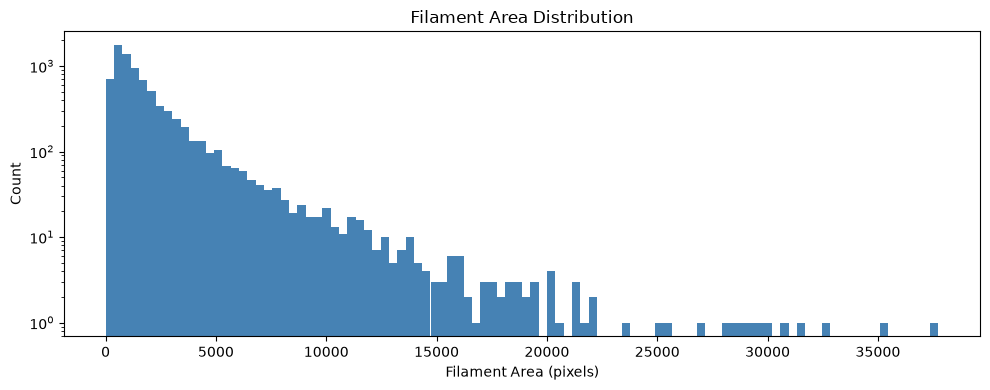

Saved: filament_area_dist.png


In [4]:
# Observatory distribution
# Filename format: YYYYMMDDHHMMSSXX.jpeg (XX = observatory code)
obs_count = Counter()
for img in data['images']:
    fname = img['file_name']
    obs = fname[14:16]  # "Bh", "Ch", "Lh", Mh, Th, Uh
    obs_count[obs] += 1

print("Observatory distribution:")
for obs, cnt in sorted(obs_count.items(), key=lambda x: -x[1]):
    print(f"  {obs}: {cnt} images ({cnt/len(data['images'])*100:.1f}%)")

# Filament area distribution
areas = [ann['area'] for ann in data['annotations']]
print(f"\nFilament area (pixels):")
print(f"  Min:    {min(areas):.0f}")
print(f"  Max:    {max(areas):.0f}")
print(f"  Mean:   {np.mean(areas):.0f}")
print(f"  Median: {np.median(areas):.0f}")

# Plot area distribution
plt.figure(figsize=(10, 4))
plt.hist(areas, bins=100, color='steelblue', edgecolor='none')
plt.xlabel('Filament Area (pixels)')
plt.ylabel('Count')
plt.title('Filament Area Distribution')
plt.yscale('log')
plt.tight_layout()
plt.savefig('filament_area_dist.png', dpi=100)
plt.show()
print("Saved: filament_area_dist.png")

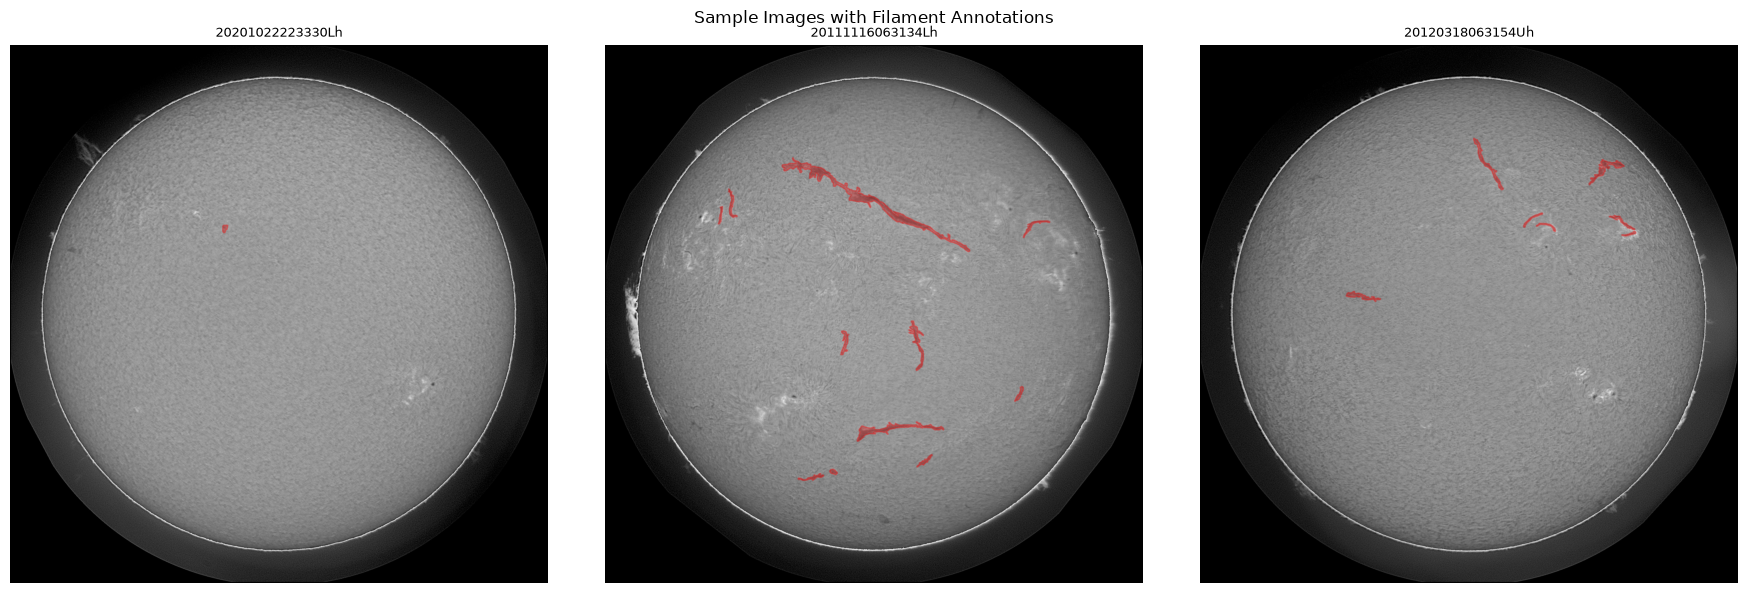

Saved: sample_annotations.png


In [5]:
# Visualize sample images with filament annotations
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
import matplotlib.patches as mpatches

# Build lookup: image_id -> annotations
ann_by_img = defaultdict(list)
for ann in data['annotations']:
    ann_by_img[ann['image_id']].append(ann)

# Build lookup: file_name -> image_id
img_lookup = {img['file_name']: img['id'] for img in data['images']}

# Pick 3 sample images
sample_files = os.listdir(TRAIN_IMG)[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, fname in zip(axes, sample_files):
    img_path = os.path.join(TRAIN_IMG, fname)
    img = np.array(Image.open(img_path).convert('L'))
    
    ax.imshow(img, cmap='gray')
    ax.set_title(fname[:16], fontsize=9)
    ax.axis('off')
    
    # Draw annotations
    img_id = img_lookup.get(fname)
    if img_id:
        anns = ann_by_img[img_id]
        for ann in anns:
            seg = ann.get('segmentation', [])
            if seg and seg[0]:
                pts = np.array(seg[0]).reshape(-1, 2)
                polygon = Polygon(pts, closed=True, fill=True,
                                  facecolor='red', alpha=0.3,
                                  edgecolor='red', linewidth=1)
                ax.add_patch(polygon)

plt.suptitle('Sample Images with Filament Annotations', fontsize=12)
plt.tight_layout()
plt.savefig('sample_annotations.png', dpi=100)
plt.show()
print(f"Saved: sample_annotations.png")

In [6]:
# Multi-annotator analysis
# image_id format: "annotatorID-imageFilename"
img_annotators = defaultdict(set)
for img in data['images']:
    img_id = str(img['id'])
    parts = img_id.split('-', 1)
    if len(parts) == 2:
        annotator_id = parts[0]
        img_name = parts[1]
        img_annotators[img_name].add(annotator_id)

annotator_counts = [len(v) for v in img_annotators.values()]
count_dist = Counter(annotator_counts)

print("Annotators per image:")
for n, cnt in sorted(count_dist.items()):
    print(f"  {n} annotator(s): {cnt} images ({cnt/len(img_annotators)*100:.1f}%)")

print(f"\nTotal unique images: {len(img_annotators)}")
print(f"Total unique annotators: {len(set(a for s in img_annotators.values() for a in s))}")

Annotators per image:
  1 annotator(s): 411 images (58.1%)
  2 annotator(s): 145 images (20.5%)
  3 annotator(s): 151 images (21.4%)

Total unique images: 707
Total unique annotators: 37


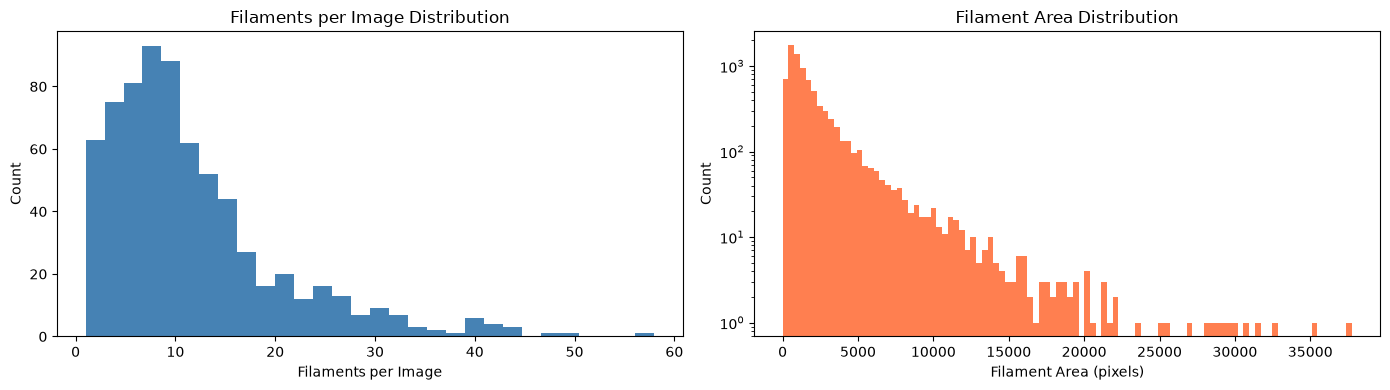

Saved: distributions.png


In [7]:
# Filaments per image distribution
img_ann = defaultdict(int)
for ann in data['annotations']:
    img_name = str(ann['image_id']).split('-', 1)[-1]
    img_ann[img_name] += 1

counts = list(img_ann.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: filaments per image
axes[0].hist(counts, bins=30, color='steelblue', edgecolor='none')
axes[0].set_xlabel('Filaments per Image')
axes[0].set_ylabel('Count')
axes[0].set_title('Filaments per Image Distribution')

# Right: filament area
areas = [ann['area'] for ann in data['annotations']]
axes[1].hist(areas, bins=100, color='coral', edgecolor='none')
axes[1].set_xlabel('Filament Area (pixels)')
axes[1].set_ylabel('Count')
axes[1].set_title('Filament Area Distribution')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig('distributions.png', dpi=100)
plt.show()
print("Saved: distributions.png")

In [8]:
# Spine analysis
spine_lengths = []
for ann in data['annotations']:
    spine = ann.get('spine', [])
    if spine:
        pts = np.array(spine).reshape(-1, 2)
        # Calculate spine length in pixels
        diffs = np.diff(pts, axis=0)
        length = np.sum(np.sqrt((diffs**2).sum(axis=1)))
        spine_lengths.append(length)

print(f"Spine data available: {len(spine_lengths)}/{len(data['annotations'])} annotations")
print(f"Spine length (pixels): min={min(spine_lengths):.0f}, max={max(spine_lengths):.0f}, mean={np.mean(spine_lengths):.0f}")

# EDA Summary
print("\n" + "="*50)
print("EDA SUMMARY")
print("="*50)
print(f"Train images:          707")
print(f"Test images:           180")
print(f"Total annotations:     8199")
print(f"Annotators:            37")
print(f"Filaments/image:       min=1, max=58, mean=11.6")
print(f"Filament area:         min=9, max=37739, median=1228 px")
print(f"Multi-annotator:       42% of images")
print(f"Unidentifiable:        37.5% of annotations")
print(f"Observatories:         6 (well balanced)")
print("="*50)
print("\nKey modeling insights:")
print("  1. Most filaments are very small (median 1228px on 2048x2048)")
print("  2. High size variation → multi-scale approach needed")
print("  3. 42% images have multiple annotators → consensus matters")
print("  4. Unidentifiable (37.5%) should be filtered in training")

Spine data available: 8199/8199 annotations
Spine length (pixels): min=12, max=1105, mean=147

EDA SUMMARY
Train images:          707
Test images:           180
Total annotations:     8199
Annotators:            37
Filaments/image:       min=1, max=58, mean=11.6
Filament area:         min=9, max=37739, median=1228 px
Multi-annotator:       42% of images
Unidentifiable:        37.5% of annotations
Observatories:         6 (well balanced)

Key modeling insights:
  1. Most filaments are very small (median 1228px on 2048x2048)
  2. High size variation → multi-scale approach needed
  3. 42% images have multiple annotators → consensus matters
  4. Unidentifiable (37.5%) should be filtered in training
